### Code to numerically solve the 1d model for solvent concentration

This code is written for a fixed domain.


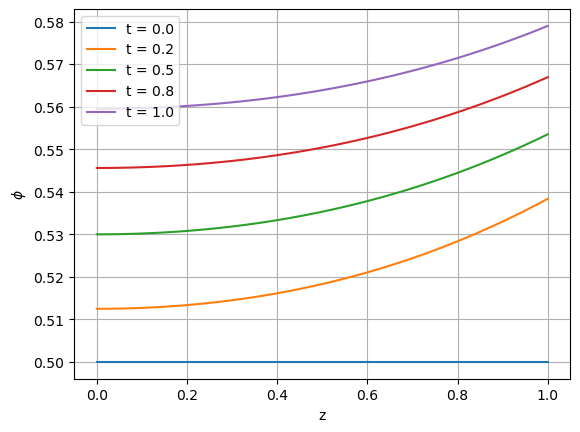

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# define physical parameters
Pe = 1
delta = 2
a = 2
phi_e = 0.75

# initial conditions
h_0 = 1
phi_0 = 0.5

# define domain parameters
dx = 0.025

# define diffusivity functions
def D(u):
    return (1-delta)*u**a + delta

def D_prime(u):
    return a*(1-delta)*u**(a-1)

def F(u, N, Pe, delta, a, phi_e, dx, D, D_prime):
    F = np.zeros(N+1) # preallocate array = size of system
    
    # derived ghost point expressions
    # 1st ghost point for first spatial derivative u_-1 = u_1
    u_ghost1 = u[1]
    u_ghost2 = u[N-1] - ((2*Pe*dx)/D(u[N]))*(1-u[N])*(u[N]- phi_e)
    
    # on substrate boundary
    F[0] = (1/Pe)* (D(u[0])*(u[1] - 2*u[0] +u_ghost1)/dx**2 + D_prime(u[0])*(u[1]-u_ghost1)/(2*dx))
    
    # at free surface
    F[-1] = (1/Pe)* (D(u[-1])*(u_ghost2 - 2*u[-1] +u[-2])/dx**2 + D_prime(u[-1])*(u_ghost2 - u[-2])/(2*dx))
    
    # interior grid points
    for i in range(1, N):
        F[i] = (1/Pe)* (D(u[i])*(u[i+1] - 2*u[i] +u[i-1])/dx**2 + D_prime(u[i])*(u[i+1] - u[i-1])/(2*dx))
        
    return F

def euler_method(F, tspan, u_0, Nt, N, Pe, delta, a, phi_e, dx, D, D_prime):
    t0, tf = tspan
    
    # time step and points
    dt = (tf - t0) / Nt
    t = np.linspace(t0, tf, Nt+1)
    
    # solution matrix
    u_sol = np.zeros((Nt+1, len(u_0)))
    
    # initial condition
    u_sol[0] = u_0
    
    # euler method
    for k in range(Nt):
        u_sol[k+1] = u_sol[k] + dt * F(u_sol[k], N, Pe, delta, a, phi_e, dx, D, D_prime)
    
    return t, u_sol


# solving

# spatial discretisation
N = int(h_0 / dx)
x = np.linspace(0, h_0, N + 1)

# time discretisation
tspan = [0, 1]

dt = 0.0001
Nt = int((tspan[1] - tspan[0]) / dt)

# initial condition
u_0 = np.full(N + 1, phi_0)

t, u_sol = euler_method(F, tspan, u_0, Nt, N, Pe, delta, a, phi_e, dx, D, D_prime)
                    
times_to_plot = [0, 0.25, 0.5, 0.75, 1]

for time in times_to_plot:
    k = np.argmin(np.abs(t - time))
    plt.plot(x, u_sol[k, :], label=f't = {t[k]:.1f}')

plt.xlabel('z')
plt.ylabel(r'$\phi$')
plt.legend()
plt.grid(True)
plt.show()          